# Probabilistic FDM — 非線形楕円型 PDE（数値解析 informed calibration）

PDE:
\[
-\Delta u + u^3 = f, \qquad (x,y)\in(0,1)^2,
\]
with \(u=0\) on \(\partial(0,1)^2\).

Prescribed solution:
\[
u^*(x,y)=\sin(\pi x)\sin(\pi y)+4\sin(4\pi x)\sin(4\pi y).
\]

観測モデル:
\[
f=\mathcal F_h(u)+\varepsilon,
\qquad
\mathcal F_h(u)=D_hu+u^3,
\qquad
\varepsilon\sim\mathcal N(0,C h^{2\tau}I).
\]

この版では hyperparameter を marginal likelihood grid search せず、FDM の数値解析情報から設定する。

- finite-difference order: \(p=2\)
- noise exponent: \(\tau=p=2\)
- length scale: \(\ell=h\)（mesh-resolved correlation scale）
- prior amplitude: \(\sigma_f=\|u_h\|_\infty\)（RMS も診断表示）
- discretisation-noise scale: \(C=\widehat C_h\) を target-grid FDM solution の coarsening defect から推定

したがって追加の \(h/2\) solve は不要。


In [1]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics
using SparseArrays
using Printf
println("Packages loaded.")


Packages loaded.


In [2]:
# 2次元 Matérnカーネル
function matern_kernel_2d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_2d(XY1, XY2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = size(XY1,1), size(XY2,1)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_2d(XY1[i,:], XY2[j,:]; ν=ν, ℓ=ℓ, σf=σf)
    end
    return K
end
println("2D Kernel defined.")


2D Kernel defined.


In [3]:
# ============================================================
# Grid setup and manufactured high-frequency solution
# ============================================================

function make_grid(Nx)
    dx = 1.0 / (Nx + 1)
    xs = [dx*i for i in 1:Nx]
    ys = [dx*j for j in 1:Nx]
    xy = hcat(
        [x for y in ys for x in xs],
        [y for y in ys for x in xs]
    )
    return dx, xy, Nx^2
end

# ------------------------------------------------------------
# Manufactured exact solution
#
# Low-frequency component + deliberately under-resolved
# high-frequency component.
#
# This makes the deterministic FDM error visible on coarse grids.
# ------------------------------------------------------------

u_true(x, y) =
    sin(pi*x)*sin(pi*y) +
    2.0*sin(6*pi*x)*sin(6*pi*y)

# -Delta u_exact
neg_lap_u(x, y) =
    2*pi^2*sin(pi*x)*sin(pi*y) +
    2.0 * 2*(6*pi)^2 * sin(6*pi*x)*sin(6*pi*y)

# Nonlinear elliptic PDE:
#   -Delta u + u^3 = f
f_rhs(x, y) =
    neg_lap_u(x,y) + u_true(x,y)^3

println("Grid and high-frequency manufactured solution defined.")


Grid and high-frequency manufactured solution defined.


In [4]:
# ============================================================
# 情報作用素 D_h = -Delta_h (線形部分, 疎行列)
# ============================================================
function make_Dh_2d(Nx, dx)
    N = Nx^2
    idx(i,j) = (j-1)*Nx + i
    rows, cols, vals = Int[], Int[], Float64[]
    for j in 1:Nx, i in 1:Nx
        k = idx(i,j)
        push!(rows,k); push!(cols,k); push!(vals, 4.0/dx^2)
        i>1   && (push!(rows,k); push!(cols,idx(i-1,j)); push!(vals,-1.0/dx^2))
        i<Nx  && (push!(rows,k); push!(cols,idx(i+1,j)); push!(vals,-1.0/dx^2))
        j>1   && (push!(rows,k); push!(cols,idx(i,j-1)); push!(vals,-1.0/dx^2))
        j<Nx  && (push!(rows,k); push!(cols,idx(i,j+1)); push!(vals,-1.0/dx^2))
    end
    return sparse(rows, cols, vals, N, N)
end

# 非線形情報作用素: F(u) = D_h*u + u^3
function nonlinear_F(u, Dh)
    return Dh*u + u.^3
end

# Jacobian: J(u) = D_h + diag(3*u^2)
function jacobian_F(u, Dh)
    return Matrix(Dh) + Diagonal(3*u.^2)
end

println("Dh and nonlinear operators defined.")


Dh and nonlinear operators defined.


In [5]:
# ============================================================
# 通常の nonlinear FDM 解 (Newton 法, prior なし)
# ============================================================
function newton_fdm(dx, Nx, f_vals; tol=1e-10, maxiter=100, verbose=true)
    N   = Nx^2
    Dh  = make_Dh_2d(Nx, dx)
    u   = zeros(N)
    converged = false

    for it in 1:maxiter
        F  = nonlinear_F(u, Dh) - f_vals
        J  = jacobian_F(u, Dh)
        du = J \ (-F)
        u .+= du

        if norm(du) < tol
            converged = true
            verbose && println("  FDM Newton converged at iter $(it)")
            break
        end
    end

    if !converged
        @warn "FDM Newton did not reach tolerance" Nx dx tol maxiter
    end
    return u
end

# ============================================================
# Coarsening-based calibration of C
#
# F_h(u) - f = c(x) h^p + higher-order terms.
# For the target-grid numerical solution u_h, evaluate the same
# nonlinear operator with a 2h Laplacian stencil:
#
#     defect = F_{2h}(u_h) - f
#
# and use the leading-order correction
#
#     c_hat = defect / ((2^p - 1) h^p).
#
# Boundary values are known to be zero, so no additional solve is needed.
# ============================================================
function estimate_C_coarsening_2d(u_h, dx, Nx; p=2)
    U = reshape(u_h, Nx, Nx)
    h2 = 2dx

    # Interior centers for which the ±2 stencil stays inside the
    # physical domain, allowing boundary value 0 at index 0 or Nx+1.
    centers = 2:(Nx-1)
    isempty(centers) && error("Nx must be at least 3 for the 2h defect estimator.")

    c_hat = Float64[]
    defect = Float64[]
    xy_defect = Tuple{Float64,Float64}[]

    # Grid-value accessor including homogeneous Dirichlet boundary.
    function uval(i, j)
        if i == 0 || i == Nx+1 || j == 0 || j == Nx+1
            return 0.0
        elseif 1 <= i <= Nx && 1 <= j <= Nx
            return U[i,j]
        else
            error("2h stencil left the physical domain")
        end
    end

    for j in centers, i in centers
        x = i * dx
        y = j * dx

        D2h_u = (
            4uval(i,j)
            - uval(i-2,j) - uval(i+2,j)
            - uval(i,j-2) - uval(i,j+2)
        ) / h2^2

        F2h_u = D2h_u + uval(i,j)^3
        d = F2h_u - f_rhs(x,y)
        c = d / ((2.0^p - 1.0) * dx^p)

        push!(defect, d)
        push!(c_hat, c)
        push!(xy_defect, (x,y))
    end

    C_hat = mean(c_hat .^ 2)
    return C_hat, c_hat, defect, xy_defect
end

# Oracle C for diagnostics only (uses prescribed exact solution).
# This is NOT used by the method.
function oracle_C_2d(dx, Nx; p=2)
    vals = Float64[]

    function ustar_grid(i,j)
        if i == 0 || i == Nx+1 || j == 0 || j == Nx+1
            return 0.0
        end
        return u_true(i*dx, j*dx)
    end

    for j in 1:Nx, i in 1:Nx
        x = i*dx
        y = j*dx
        Dh_u = (
            4ustar_grid(i,j)
            - ustar_grid(i-1,j) - ustar_grid(i+1,j)
            - ustar_grid(i,j-1) - ustar_grid(i,j+1)
        ) / dx^2
        e = Dh_u + u_true(x,y)^3 - f_rhs(x,y)
        push!(vals, e / dx^p)
    end

    return mean(vals .^ 2)
end

# ============================================================
# MAP 推定 (Newton / Gauss-Newton, prior + likelihood)
# ============================================================
function newton_map(dx, Nx, f_vals, K;
                    C=1.0, tau=2, u0=nothing,
                    tol=1e-10, maxiter=100, verbose=true)
    N         = Nx^2
    Dh        = make_Dh_2d(Nx, dx)
    u         = u0 === nothing ? zeros(N) : copy(u0)
    noise_var = C * dx^(2*tau)
    Sigma_inv = (1.0/noise_var) * I
    K_inv     = inv(Matrix(K) + 1e-8*I)
    converged = false

    for it in 1:maxiter
        F_val = nonlinear_F(u, Dh) - f_vals
        J     = jacobian_F(u, Dh)
        H     = J' * Sigma_inv * J + K_inv
        g     = J' * Sigma_inv * F_val + K_inv * u
        du    = H \ (-g)
        u .+= du

        if norm(du) < tol
            converged = true
            verbose && println("  MAP Newton converged at iter $(it)")
            break
        end
    end

    if !converged
        @warn "MAP Newton did not reach tolerance" Nx dx tol maxiter
    end
    return u
end

println("Newton and calibration functions defined.")


Newton and calibration functions defined.


In [6]:
# ============================================================
# Laplace 近似 (正しい定式化)
# 観測モデル: f = F(u) + epsilon
# 事後平均: mu_post = u_map　
# 事後分散: Sigma_post = K - K J^T (J K J^T + Sigma)^{-1} J K
# ============================================================
function laplace_posterior(u_map, xy, dx, Nx, K;
                            C=1.0, tau=2)
    N           = Nx^2
    Dh          = make_Dh_2d(Nx, dx)
    J           = jacobian_F(u_map, Dh)
    noise_var   = C * dx^(2*tau)
    Sigma_noise = noise_var * I

    JK       = J * K
    M        = Symmetric(JK * J' + Sigma_noise)
    L        = cholesky(M).L

    mu_post  = u_map
    V        = L \ JK
    Sig_post = K - V' * V
    std_post = sqrt.(max.(diag(Sig_post), 0.0))

    return mu_post, std_post
end
println("laplace_posterior defined.")


laplace_posterior defined.


In [7]:
# ============================================================
# Numerical-analysis-informed hyperparameter calibration
# ============================================================
function calibrate_hyperparameters(u_fdm, dx, Nx;
                                   p_order=2,
                                   sigma_rule=:max,
                                   lengthscale_factor=1.0,
                                   show_oracle=true)

    tau = p_order

    # Prior amplitude from the deterministic numerical solution.
    sigma_rms = sqrt(mean(u_fdm .^ 2))
    sigma_max = maximum(abs.(u_fdm))

    sigma_f = if sigma_rule == :rms
        sigma_rms
    elseif sigma_rule == :max
        sigma_max
    else
        error("sigma_rule must be :rms or :max")
    end

    # Mesh-resolved prior length scale.
    ell = lengthscale_factor * dx

    # Discretisation-noise scale from the coarsening defect.
    C_hat, c_hat, defect, xy_defect = estimate_C_coarsening_2d(
        u_fdm, dx, Nx; p=p_order
    )

    println("\n=== Numerics-informed calibration ===")
    println("h          = $(round(dx, sigdigits=6))")
    println("p = tau    = $(p_order)")
    println("ell        = $(round(ell, sigdigits=6))  [$(lengthscale_factor) * h]")
    println("sigma_rms  = $(round(sigma_rms, sigdigits=6))")
    println("sigma_max  = $(round(sigma_max, sigdigits=6))")
    println("sigma_used = $(round(sigma_f, sigdigits=6))  [rule=$(sigma_rule)]")
    println("C_hat      = $(round(C_hat, sigdigits=6))")
    println("RMS(c_hat) = $(round(sqrt(C_hat), sigdigits=6))")
    println("defect pts = $(length(c_hat))")

    if show_oracle
        C_oracle = oracle_C_2d(dx, Nx; p=p_order)
        rel = abs(C_hat - C_oracle) / C_oracle
        println("C_oracle   = $(round(C_oracle, sigdigits=6))  [diagnostic only]")
        println("rel. error = $(round(rel, sigdigits=5))")
    end

    return sigma_f, ell, C_hat
end

println("Numerics-informed calibration defined.")


Numerics-informed calibration defined.


In [8]:
# ============================================================
# Settings
# ============================================================

Nx      = 8
nu_ker  = 1.5
p_order = 2

# Hyperparameter policy
sigma_rule = :max
ell_factors = [0.5, 0.75, 1.0, 1.5, 2.0]

dx, xy, N = make_grid(Nx)

println("Nx=$(Nx), N=$(N), dx=$(round(dx,digits=6))")
println("Exact solution:")
println("  sin(pi x) sin(pi y) + 2 sin(6pi x) sin(6pi y)")

u_star = [
    u_true(xy[k,1], xy[k,2])
    for k in 1:N
]

f_vals = [
    f_rhs(xy[k,1], xy[k,2])
    for k in 1:N
]

println("max(|u_star|) = $(round(maximum(abs.(u_star)), digits=6))")
println("max(|f_vals|) = $(round(maximum(abs.(f_vals)), digits=6))")

println("\nRunning deterministic nonlinear FDM Newton...")

u_fdm = newton_fdm(
    dx,
    Nx,
    f_vals
)

err_fdm =
    maximum(
        abs.(
            u_fdm -
            u_star
        )
    )

rmse_fdm =
    sqrt(
        mean(
            (u_fdm-u_star).^2
        )
    )

println("FDM L∞ error = $(round(err_fdm, digits=6))")
println("FDM RMSE     = $(round(rmse_fdm, digits=6))")
println("h^2          = $(round(dx^2, digits=6))")


Nx=8, N=64, dx=0.111111
Exact solution:
  sin(pi x) sin(pi y) + 2 sin(6pi x) sin(6pi y)
max(|u_star|) = 2.469846
max(|f_vals|) = 1100.127684

Running deterministic nonlinear FDM Newton...
  FDM Newton converged at iter 5
FDM L∞ error = 0.797161
FDM RMSE     = 0.512871
h^2          = 0.012346


In [9]:
# ============================================================
# Proposed hyperparameters:
# sigma_f from FDM, C from defect, ell from h-scaled LML grid
# ============================================================

tau_fixed = p_order

# sigma_f: same rule as before
sigma_rms = sqrt(mean(u_fdm.^2))
sigma_max = maximum(abs.(u_fdm))

best_sf = if sigma_rule == :rms
    sigma_rms
elseif sigma_rule == :max
    sigma_max
else
    error("sigma_rule must be :rms or :max")
end

# C: same coarsening-defect estimator as before
best_C, c_hat, defect, xy_defect =
    estimate_C_coarsening_2d(
        u_fdm, dx, Nx;
        p=p_order
    )

# ell candidates around h
ell_grid = dx .* ell_factors

# ------------------------------------------------------------
# Laplace approximate log marginal likelihood for ell
# ------------------------------------------------------------
function nonlinear_lml_ell(
    ell;
    u0=u_fdm,
    dx=dx,
    Nx=Nx,
    xy=xy,
    f_vals=f_vals,
    sigma_f=best_sf,
    C=best_C,
    nu=nu_ker,
    tau=tau_fixed
)
    N = Nx^2

    K = Symmetric(
        kernel_matrix_2d(
            xy, xy;
            ν=nu,
            ℓ=ell,
            σf=sigma_f
        ) + 1e-8*I
    )

    u_map = newton_map(
        dx, Nx, f_vals, K;
        C=C,
        tau=tau,
        u0=u0,
        verbose=false
    )

    Dh = make_Dh_2d(Nx, dx)
    r  = nonlinear_F(u_map, Dh) - f_vals
    J  = jacobian_F(u_map, Dh)

    noise_var = C * dx^(2tau)

    Kmat  = Matrix(K)
    Kchol = cholesky(Symmetric(Kmat))

    Kinv_u = Kchol \ u_map

    data_term =
        0.5 * dot(r,r) / noise_var

    prior_term =
        0.5 * dot(u_map, Kinv_u)

    Hpost = Symmetric(
        (J' * J) / noise_var +
        inv(Kmat)
    )

    Hchol = cholesky(Hpost)

    logdet_H =
        2sum(log, diag(Hchol.L))

    logdet_K =
        2sum(log, diag(Kchol.L))

    logdet_S =
        N * log(noise_var)

    return (
        -(data_term + prior_term)
        - 0.5*logdet_H
        - 0.5*logdet_K
        - 0.5*logdet_S
        - 0.5*N*log(2π)
    )
end

ell_lml = fill(-Inf, length(ell_grid))

for (i, ell) in enumerate(ell_grid)
    try
        ell_lml[i] = nonlinear_lml_ell(ell)
    catch err
        @warn "LML failed" ell exception=(err, catch_backtrace())
        ell_lml[i] = -Inf
    end
end

best_idx = argmax(ell_lml)
best_l   = ell_grid[best_idx]

println("\n=== Proposed hyperparameters ===")
@printf("h          = %.6g\n", dx)
@printf("sigma_f    = %.6g\n", best_sf)
@printf("C_hat      = %.6g\n", best_C)
println("ell_grid   = ", round.(ell_grid, sigdigits=6))

println("\n=== ell marginal-likelihood table ===")
@printf("%-12s %-16s\n", "ell", "log marginal")
println("-"^30)

for (ell, lml) in zip(ell_grid, ell_lml)
    @printf("%-12.6g %-16.6f\n", ell, lml)
end

println("-"^30)
@printf("best ell   = %.6g\n", best_l)
@printf("best LML   = %.6g\n", ell_lml[best_idx])

# ------------------------------------------------------------
# GP prior with selected ell
# ------------------------------------------------------------
K_prior = Symmetric(
    kernel_matrix_2d(
        xy, xy;
        ν=nu_ker,
        ℓ=best_l,
        σf=best_sf
    ) + 1e-8*I
)

println("\nRunning MAP Newton...")

u_map = newton_map(
    dx, Nx, f_vals, K_prior;
    C=best_C,
    tau=tau_fixed,
    u0=u_fdm
)

err_map =
    maximum(
        abs.(
            u_map -
            u_star
        )
    )

println("MAP L∞ error = $(round(err_map, digits=6))")
println("FDM L∞ error = $(round(err_fdm, digits=6))")

mu_post, std_post =
    laplace_posterior(
        u_map,
        xy,
        dx,
        Nx,
        K_prior;
        C=best_C,
        tau=tau_fixed
    )

println("max std = $(round(maximum(std_post), digits=6))")



=== Numerics-informed calibration ===
h          = 0.111111
p = tau    = 2
ell        = 0.111111  [1.0 * h]
sigma_rms  = 1.70872
sigma_max  = 3.02845
sigma_used = 3.02845  [rule=max]
C_hat      = 2.04281e8
RMS(c_hat) = 14292.7
defect pts = 36
C_oracle   = 4.18928e8  [diagnostic only]
rel. error = 0.51237

Running MAP Newton...
  MAP Newton converged at iter 16
MAP L∞ error = 0.990459
FDM L∞ error = 0.797161
max std      = 1.30062


In [10]:
# ============================================================
# LML over ell = h * [0.5, 0.75, 1, 1.5, 2]
# ============================================================

p_lml = plot(
    ell_grid,
    ell_lml;
    marker=:circle,
    lw=2,
    xlabel="ell",
    ylabel="log marginal likelihood",
    title="Length-scale selection",
    label="LML",
    framestyle=:box
)

scatter!(
    p_lml,
    [best_l],
    [maximum(ell_lml)];
    marker=:star5,
    markersize=9,
    color=:red,
    label="selected ell"
)

display(p_lml)



=== Optional ell/h sensitivity ===
ell/h=0.75: ell=0.083333, MAP L∞=1.2077, max std=1.2085
ell/h=1.0: ell=0.11111, MAP L∞=0.99046, max std=1.3006
ell/h=1.5: ell=0.16667, MAP L∞=0.72672, max std=1.3687


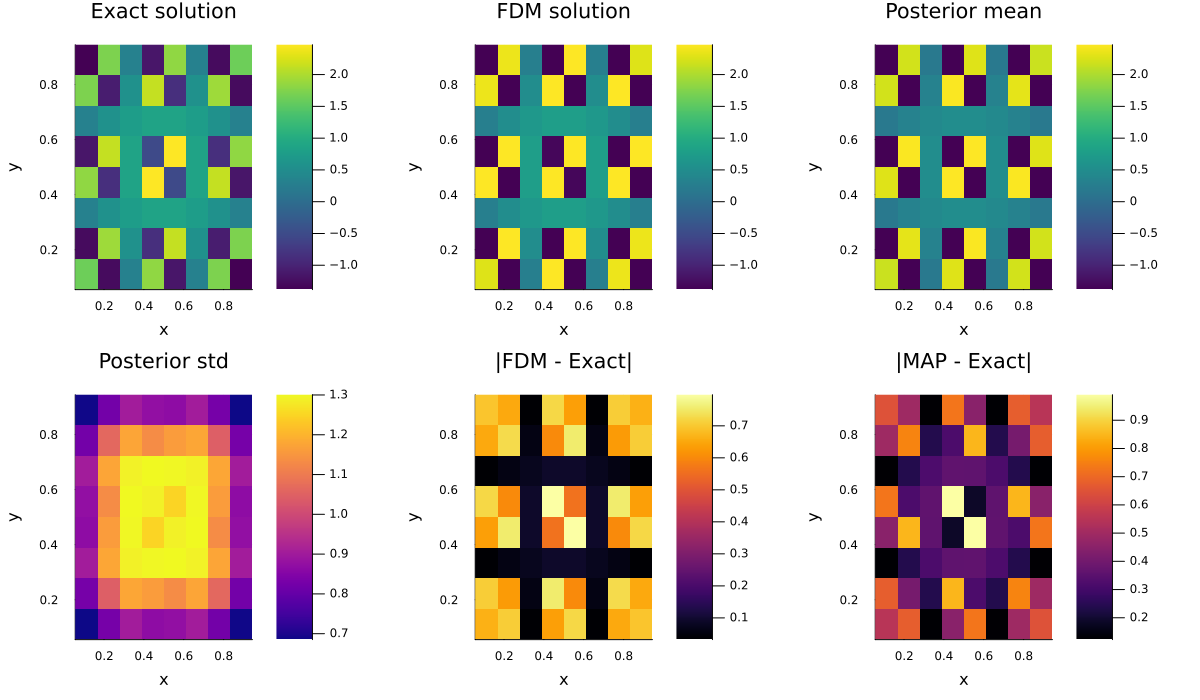

Saved: nonlinear_elliptic_posterior.png
Saved: nonlinear_elliptic_slices.png


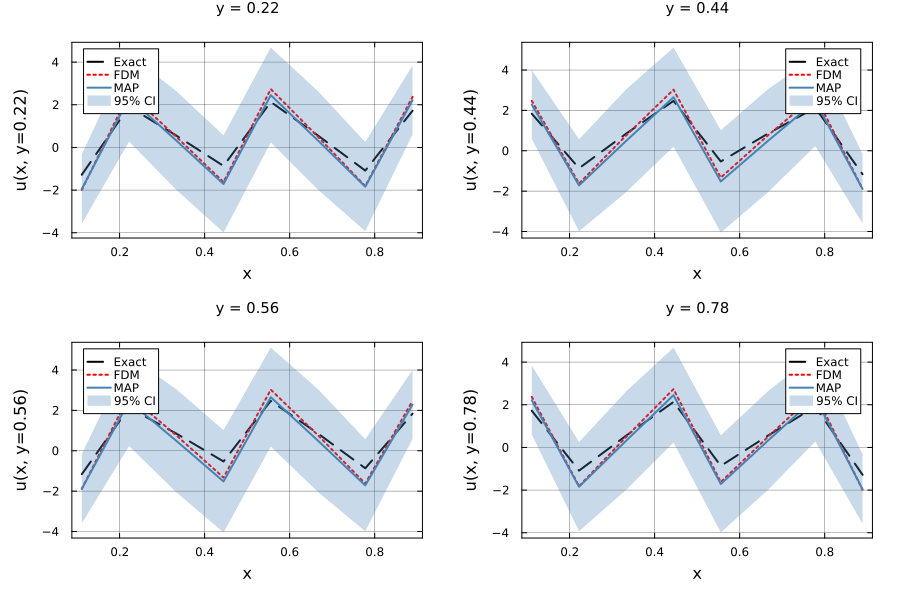

In [11]:
# ============================================================
# 可視化 1: ヒートマップ
# ============================================================
xs_int = [dx*(i) for i in 1:Nx]
ys_int = [dx*(j) for j in 1:Nx]

function to_grid(u, Nx); reshape(u, Nx, Nx); end

U_star    = to_grid(u_star,   Nx)
U_fdm     = to_grid(u_fdm,    Nx)
U_map     = to_grid(mu_post,  Nx)
U_std     = to_grid(std_post, Nx)
U_err_fdm = to_grid(abs.(u_fdm   - u_star), Nx)
U_err_map = to_grid(abs.(mu_post - u_star), Nx)

clim_u = (minimum(U_star), maximum(U_star))

p1 = heatmap(xs_int, ys_int, U_star';    title="Exact solution",  color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p2 = heatmap(xs_int, ys_int, U_fdm';     title="FDM solution",    color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p3 = heatmap(xs_int, ys_int, U_map';     title="Posterior mean",  color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p4 = heatmap(xs_int, ys_int, U_std';     title="Posterior std",   color=:plasma,  xlabel="x", ylabel="y")
p5 = heatmap(xs_int, ys_int, U_err_fdm'; title="|FDM - Exact|",  color=:inferno, xlabel="x", ylabel="y")
p6 = heatmap(xs_int, ys_int, U_err_map'; title="|MAP - Exact|",  color=:inferno, xlabel="x", ylabel="y")

fig = plot(p1, p2, p3, p4, p5, p6; layout=(2,3), size=(1200,700), margin=5*Plots.mm)
display(fig)
savefig(fig, "nonlinear_elliptic_posterior.png")
println("Saved: nonlinear_elliptic_posterior.png")

# ============================================================
# 可視化 2: y = 0.2, 0.4, 0.6, 0.8 での断面
# ============================================================
y_slices = [0.2, 0.4, 0.6, 0.8]
plots_slice = []

for y_target in y_slices
    # y_target に最も近いグリッド点のインデックスを探す
    j_idx = argmin(abs.(ys_int .- y_target))
    y_actual = ys_int[j_idx]

    # 断面のデータ
    u_exact_slice = U_star[:, j_idx]
    u_fdm_slice   = U_fdm[:,  j_idx]
    u_map_slice   = U_map[:,  j_idx]
    u_std_slice   = U_std[:,  j_idx]

    pp = plot(xs_int, u_exact_slice;
        label="Exact", lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(x, y=$(round(y_actual,digits=2)))",
        title="y = $(round(y_actual,digits=2))",
        titlefontsize=10, legendfontsize=8,
        grid=true, gridalpha=0.3, framestyle=:box)
    plot!(pp, xs_int, u_fdm_slice;
        label="FDM", lw=2, ls=:dot, color=:red)
    plot!(pp, xs_int, u_map_slice;
        label="MAP", lw=2, color=:steelblue)
    plot!(pp, xs_int, u_map_slice .+ 1.96 .* u_std_slice;
        lw=0, fillalpha=0, label=false, color=:steelblue)
    plot!(pp, xs_int, u_map_slice .- 1.96 .* u_std_slice;
        lw=0, fillrange=u_map_slice .+ 1.96 .* u_std_slice,
        fillalpha=0.3, linealpha=0, label="95% CI", color=:steelblue)
    push!(plots_slice, pp)
end

fig_slice = plot(plots_slice...;
    layout=(2,2), size=(900,600), margin=5*Plots.mm)
display(fig_slice)
savefig(fig_slice, "nonlinear_elliptic_slices.png")
println("Saved: nonlinear_elliptic_slices.png")



=== Nx sweep ===

=== Numerics-informed calibration ===
h          = 0.2
p = tau    = 2
ell        = 0.2  [1.0 * h]
sigma_rms  = 4.35184
sigma_max  = 6.13321
sigma_used = 6.13321  [rule=max]
C_hat      = 6.85724e7
RMS(c_hat) = 8280.85
defect pts = 4
C_oracle   = 2.74016e8  [diagnostic only]
rel. error = 0.74975
Nx=4, h=0.2: sigma=6.133, ell=0.2, C=6.8572e7, FDM err=4.7563, MAP err=4.5391, max std=3.1613

=== Numerics-informed calibration ===
h          = 0.142857
p = tau    = 2
ell        = 0.142857  [1.0 * h]
sigma_rms  = 2.21918
sigma_max  = 4.09096
sigma_used = 4.09096  [rule=max]
C_hat      = 2.85466e8
RMS(c_hat) = 16895.7
defect pts = 16
C_oracle   = 3.734e8  [diagnostic only]
rel. error = 0.2355
Nx=6, h=0.1429: sigma=4.091, ell=0.1429, C=2.8547e8, FDM err=2.0052, MAP err=2.3747, max std=2.4376

=== Numerics-informed calibration ===
h          = 0.111111
p = tau    = 2
ell        = 0.111111  [1.0 * h]
sigma_rms  = 1.70872
sigma_max  = 3.02845
sigma_used = 3.02845  [rule=max]
C_ha

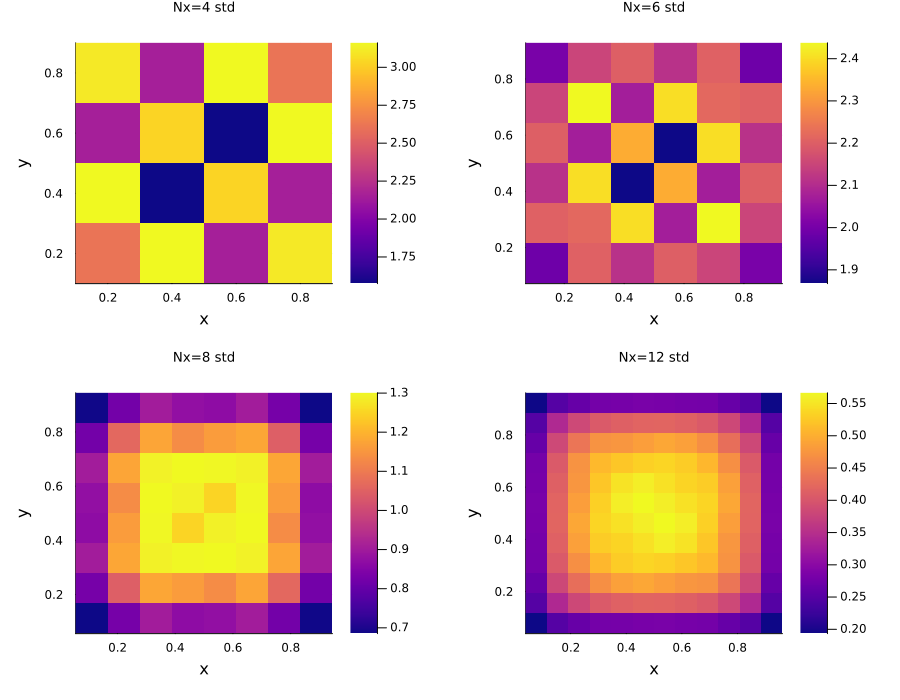

In [12]:
# ============================================================
# Nx sweep with the same h-scaled ell grid
# ============================================================

Nx_list = [4, 6, 8, 12]

println("\n=== Nx sweep ===")

for nx in Nx_list

    dxx, xym, Nn =
        make_grid(nx)

    u_st = [
        u_true(xym[k,1], xym[k,2])
        for k in 1:Nn
    ]

    f_vl = [
        f_rhs(xym[k,1], xym[k,2])
        for k in 1:Nn
    ]

    u_fd =
        newton_fdm(
            dxx,
            nx,
            f_vl;
            verbose=false
        )

    sf = if sigma_rule == :rms
        sqrt(mean(u_fd.^2))
    else
        maximum(abs.(u_fd))
    end

    Cc, _, _, _ =
        estimate_C_coarsening_2d(
            u_fd,
            dxx,
            nx;
            p=p_order
        )

    ell_grid_nx =
        dxx .* ell_factors

    scores_nx =
        fill(
            -Inf,
            length(ell_grid_nx)
        )

    for (i, ell) in enumerate(ell_grid_nx)

        try
            Kp = Symmetric(
                kernel_matrix_2d(
                    xym,
                    xym;
                    ν=nu_ker,
                    ℓ=ell,
                    σf=sf
                ) + 1e-8*I
            )

            um = newton_map(
                dxx,
                nx,
                f_vl,
                Kp;
                C=Cc,
                tau=p_order,
                u0=u_fd,
                verbose=false
            )

            Dh = make_Dh_2d(nx, dxx)
            r  = nonlinear_F(um, Dh) - f_vl
            J  = jacobian_F(um, Dh)

            nv = Cc * dxx^(2p_order)

            Km = Matrix(Kp)
            Kch = cholesky(Symmetric(Km))

            Hpost = Symmetric(
                (J' * J) / nv +
                inv(Km)
            )

            Hch =
                cholesky(Hpost)

            scores_nx[i] =
                -0.5*dot(r,r)/nv -
                0.5*dot(um, Kch \ um) -
                sum(log, diag(Hch.L)) -
                sum(log, diag(Kch.L)) -
                0.5*Nn*log(nv) -
                0.5*Nn*log(2π)

        catch err
            @warn "Nx sweep LML failed" nx ell exception=(err, catch_backtrace())
        end
    end

    ibest =
        argmax(scores_nx)

    ell =
        ell_grid_nx[ibest]

    println(
        "Nx=$(nx), " *
        "h=$(round(dxx,sigdigits=4)), " *
        "ell_grid=$(round.(ell_grid_nx,sigdigits=4)), " *
        "best ell=$(round(ell,sigdigits=4)), " *
        "C=$(round(Cc,sigdigits=5)), " *
        "sigma=$(round(sf,sigdigits=4))"
    )
end


### Notes on calibration

`C_oracle` is printed only because this manufactured example has a known exact solution. It is **not** used in PFDM inference. Its purpose is to diagnose whether the coarsening estimator is in the asymptotic regime.

For a real nonlinear PDE with unknown exact solution, the method uses only the deterministic target-grid solution `u_fdm`, the mesh width `h`, and the known PDE right-hand side.


## Fine-grid evaluation for the high-frequency example

The PFDM is trained on the coarse \(N_x=8\) grid, but evaluated on a fine \(101\times101\) test grid.

This makes it easier to see whether the posterior uncertainty actually covers the discretisation/interpolation error induced by the deliberately under-resolved \(6\pi\) mode.


In [14]:
# ============================================================
# Full Laplace covariance on training grid
# ============================================================

function laplace_posterior_full(
    u_map, xy, dx, Nx, K;
    C=1.0, tau=2
)
    Dh = make_Dh_2d(Nx, dx)
    J  = jacobian_F(u_map, Dh)

    noise_var   = C * dx^(2tau)
    Sigma_noise = noise_var * I

    JK = J * K
    M  = Symmetric(JK * J' + Sigma_noise)
    L  = cholesky(M).L

    V = L \ JK

    Sigma_train =
        Matrix(K) - V' * V

    return u_map, Sigma_train
end


function extend_laplace_to_test(
    mu_train,
    Sigma_train,
    xy_train,
    xy_test,
    K_train;
    nu=1.5,
    ell=1.0,
    sigma_f=1.0
)
    Ktr = Matrix(K_train)

    K_cross = kernel_matrix_2d(
        xy_test,
        xy_train;
        ν=nu,
        ℓ=ell,
        σf=sigma_f
    )

    Lk = cholesky(
        Symmetric(
            Ktr +
            1e-10*I
        )
    )

    A = (K_cross / Lk.U) / Lk.L

    mu_test =
        A * mu_train

    prior_cond_var =
        sigma_f^2 .-
        vec(
            sum(
                A .* K_cross,
                dims=2
            )
        )

    B =
        A * Sigma_train

    posterior_extra =
        vec(
            sum(
                B .* A,
                dims=2
            )
        )

    var_test =
        max.(
            prior_cond_var .+
            posterior_extra,
            0.0
        )

    std_test =
        sqrt.(var_test)

    return mu_test, std_test
end


extend_laplace_to_test (generic function with 1 method)

In [15]:
# ============================================================
# Fine test-grid evaluation
# ============================================================

Nx_train = Nx
Nx_test  = 101

mu_train, Sigma_train =
    laplace_posterior_full(
        u_map,
        xy,
        dx,
        Nx_train,
        K_prior;
        C=best_C,
        tau=tau_fixed
    )

h_test =
    1.0 / (Nx_test + 1)

xs_test = [
    h_test*i
    for i in 1:Nx_test
]

ys_test = [
    h_test*j
    for j in 1:Nx_test
]

xy_test = hcat(
    [x for y in ys_test for x in xs_test],
    [y for y in ys_test for x in xs_test]
)

u_true_test = [
    u_true(
        xy_test[k,1],
        xy_test[k,2]
    )
    for k in 1:size(xy_test,1)
]

mu_test, std_test =
    extend_laplace_to_test(
        mu_train,
        Sigma_train,
        xy,
        xy_test,
        K_prior;
        nu=nu_ker,
        ell=best_l,
        sigma_f=best_sf
    )

err =
    u_true_test .-
    mu_test

abs_err =
    abs.(err)

rmse =
    sqrt(
        mean(
            err.^2
        )
    )

linf =
    maximum(abs_err)

coverage =
    mean(
        abs_err .<=
        1.96 .* std_test
    )

z =
    err ./ max.(
        std_test,
        1e-12
    )

z_rms =
    sqrt(
        mean(
            z.^2
        )
    )

mean_halfwidth =
    mean(
        1.96 .* std_test
    )

println("==============================================")
println("High-frequency fine-grid evaluation")
println("==============================================")

@printf("Nx_train = %d\n", Nx_train)
@printf("Nx_test  = %d\n", Nx_test)
@printf("h_train  = %.6g\n", dx)
@printf("ell      = %.6g\n", best_l)
@printf("sigma_f  = %.6g\n", best_sf)
@printf("C_hat    = %.6g\n", best_C)

@printf("RMSE     = %.6g\n", rmse)
@printf("Linf     = %.6g\n", linf)
@printf("coverage = %.3f\n", coverage)
@printf("z_RMS    = %.3f\n", z_rms)
@printf("mean 95%% half-width = %.6g\n", mean_halfwidth)


High-frequency fine-grid evaluation
Nx_train = 8
Nx_test  = 101
h_train  = 0.111111
ell      = 0.111111
sigma_f  = 3.02845
C_hat    = 2.04281e+08
RMSE     = 0.337832
Linf     = 1.0001
coverage = 1.000
z_RMS    = 0.217
mean 95% half-width = 3.34281


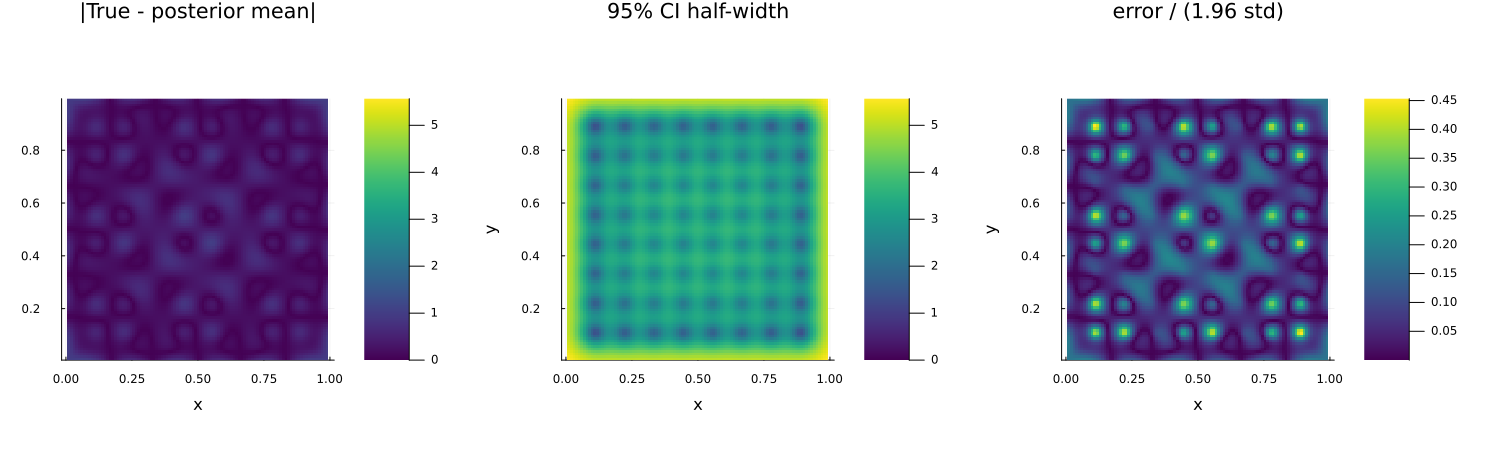

"/Users/shoji/Project_with_Jon/Bratu-Gelfand/nonlinear_highfreq_finetest_heatmaps.png"

In [16]:
# ============================================================
# Fine-grid heatmaps
# ============================================================

E_post = reshape(
    abs_err,
    Nx_test,
    Nx_test
)'

CI95 = reshape(
    1.96 .* std_test,
    Nx_test,
    Nx_test
)'

ratio95 = reshape(
    abs_err ./ max.(
        1.96 .* std_test,
        1e-12
    ),
    Nx_test,
    Nx_test
)'

common_max = maximum(
    vcat(
        vec(E_post),
        vec(CI95)
    )
)

p1 = heatmap(
    xs_test,
    ys_test,
    E_post;
    title="|True - posterior mean|",
    xlabel="x",
    ylabel="y",
    color=:viridis,
    clim=(0,common_max),
    aspect_ratio=:equal
)

p2 = heatmap(
    xs_test,
    ys_test,
    CI95;
    title="95% CI half-width",
    xlabel="x",
    ylabel="y",
    color=:viridis,
    clim=(0,common_max),
    aspect_ratio=:equal
)

p3 = heatmap(
    xs_test,
    ys_test,
    ratio95;
    title="error / (1.96 std)",
    xlabel="x",
    ylabel="y",
    color=:viridis,
    aspect_ratio=:equal
)

fig_hf = plot(
    p1,p2,p3;
    layout=(1,3),
    size=(1500,470),
    margin=2*Plots.mm
)

display(fig_hf)

savefig(
    fig_hf,
    "nonlinear_highfreq_finetest_heatmaps.png"
)


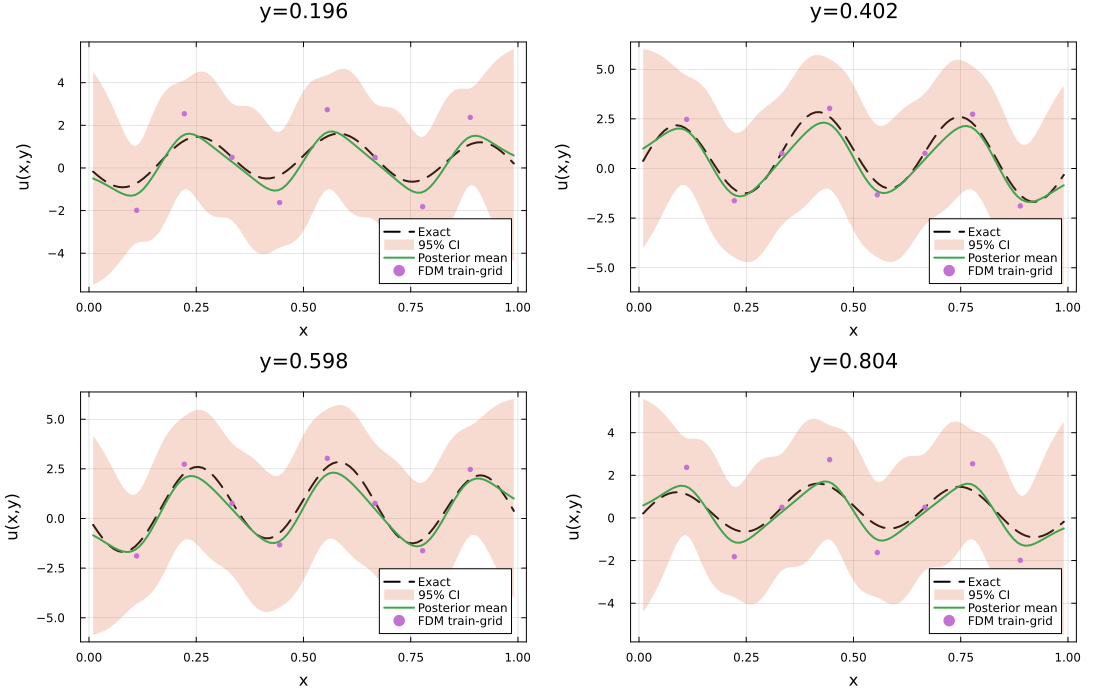

"/Users/shoji/Project_with_Jon/Bratu-Gelfand/nonlinear_highfreq_finetest_slices.png"

In [17]:
# ============================================================
# Slice plots: Exact / FDM / posterior mean / 95% CI
# ============================================================

MU =
    reshape(
        mu_test,
        Nx_test,
        Nx_test
    )'

STD =
    reshape(
        std_test,
        Nx_test,
        Nx_test
    )'

TRUE =
    reshape(
        u_true_test,
        Nx_test,
        Nx_test
    )'

# Training-grid FDM for overlay
U_FDM =
    reshape(
        u_fdm,
        Nx,
        Nx
    )'

xs_train =
    [dx*i for i in 1:Nx]

ys_train =
    [dx*j for j in 1:Nx]

y_slices =
    [0.2,0.4,0.6,0.8]

plots_hf = []

for y_target in y_slices

    jtest =
        argmin(
            abs.(
                ys_test .-
                y_target
            )
        )

    jtrain =
        argmin(
            abs.(
                ys_train .-
                y_target
            )
        )

    y_actual =
        ys_test[jtest]

    us =
        TRUE[jtest,:]

    μs =
        MU[jtest,:]

    σs =
        STD[jtest,:]

    ufdm_s =
        U_FDM[jtrain,:]

    pp = plot(
        xs_test,
        us;
        label="Exact",
        lw=2,
        ls=:dash,
        color=:black,
        xlabel="x",
        ylabel="u(x,y)",
        title="y=$(round(y_actual,digits=3))",
        framestyle=:box
    )

    plot!(
        pp,
        xs_test,
        μs .+
        1.96 .* σs;
        fillrange=
            μs .-
            1.96 .* σs,
        fillalpha=0.25,
        linealpha=0,
        label="95% CI"
    )

    plot!(
        pp,
        xs_test,
        μs;
        label="Posterior mean",
        lw=2
    )

    scatter!(
        pp,
        xs_train,
        ufdm_s;
        label="FDM train-grid",
        markersize=3,
        markerstrokewidth=0
    )

    push!(
        plots_hf,
        pp
    )
end

fig_slices_hf = plot(
    plots_hf...;
    layout=(2,2),
    size=(1100,700),
    margin=4*Plots.mm
)

display(fig_slices_hf)

savefig(
    fig_slices_hf,
    "nonlinear_highfreq_finetest_slices.png"
)


## Final comparison figure

Exact, fine-grid posterior mean/95% CI, and the coarse standard-FDM numerical solution are shown together.

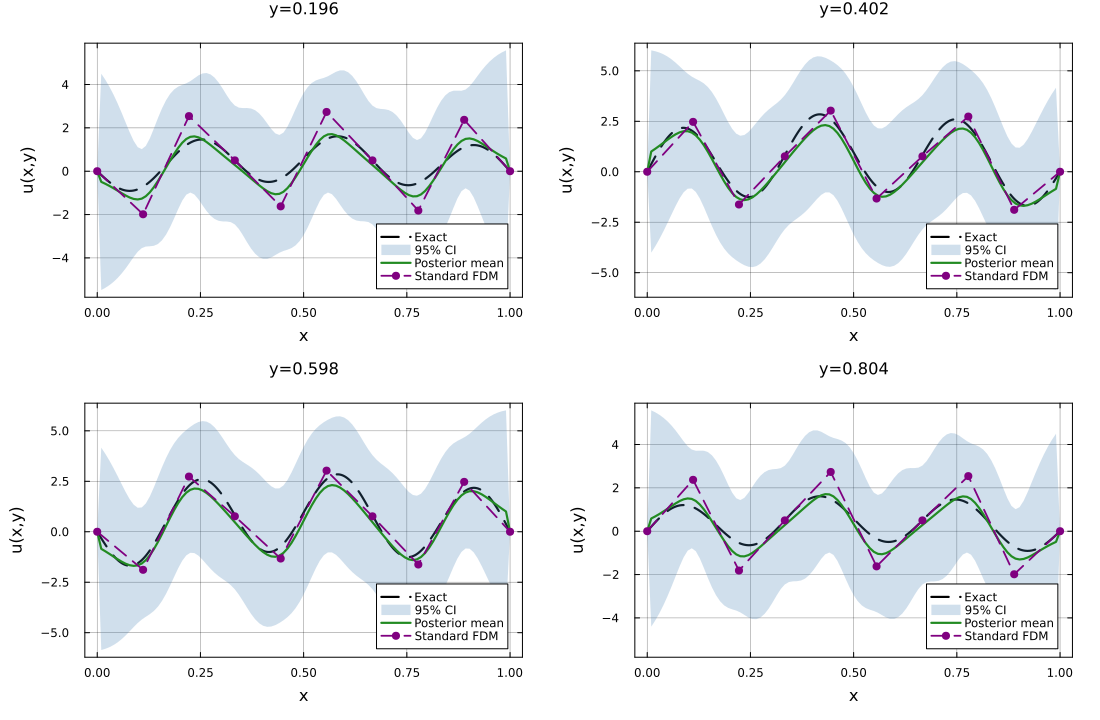

Saved: nonlinear_highfreq_final_slices_with_fdm_boundary.png


In [18]:
# ============================================================
# Final paper-style slice plots with boundary points
#
# Exact            : very fine resolution (501 points)
# Posterior mean   : fine test grid + boundary
# 95% CI           : fine test grid + boundary
# Standard FDM     : coarse training grid + boundary
# ============================================================

x_exact = collect(range(0.0, 1.0, length=501))

xs_train = [dx*i for i in 1:Nx]
ys_train = [dx*j for j in 1:Nx]

U_FDM = reshape(u_fdm, Nx, Nx)'

y_slices = [0.2, 0.4, 0.6, 0.8]

plots_final = []

for y_target in y_slices

    # --------------------------------------------------------
    # Fine-test slice closest to requested y
    # --------------------------------------------------------
    j_test = argmin(abs.(ys_test .- y_target))
    y_actual = ys_test[j_test]

    # Training-grid slice closest to the same physical y
    j_train = argmin(abs.(ys_train .- y_actual))

    # --------------------------------------------------------
    # Exact solution: fine x-grid including boundaries
    # --------------------------------------------------------
    u_exact_fine = [
        u_true(x, y_actual)
        for x in x_exact
    ]

    # --------------------------------------------------------
    # Fine-test posterior
    # --------------------------------------------------------
    u_post_slice = MU[j_test, :]
    u_std_slice  = STD[j_test, :]

    # Add exact Dirichlet boundary values
    xs_post = vcat(
        0.0,
        xs_test,
        1.0
    )

    u_post_plot = vcat(
        0.0,
        u_post_slice,
        0.0
    )

    # Boundary condition is exact -> std = 0
    u_std_plot = vcat(
        0.0,
        u_std_slice,
        0.0
    )

    lower = u_post_plot .- 1.96 .* u_std_plot
    upper = u_post_plot .+ 1.96 .* u_std_plot

    # --------------------------------------------------------
    # Coarse FDM numerical solution + boundaries
    # --------------------------------------------------------
    u_fdm_slice = U_FDM[j_train, :]

    xs_fdm = vcat(
        0.0,
        xs_train,
        1.0
    )

    u_fdm_plot = vcat(
        0.0,
        u_fdm_slice,
        0.0
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------
    pp = plot(
        x_exact,
        u_exact_fine;
        label="Exact",
        lw=2.2,
        ls=:dash,
        color=:black,
        xlabel="x",
        ylabel="u(x,y)",
        title="y=$(round(y_actual,digits=3))",
        titlefontsize=11,
        legendfontsize=8,
        grid=true,
        gridalpha=0.25,
        framestyle=:box
    )

    # 95% credible interval
    plot!(
        pp,
        xs_post,
        upper;
        fillrange=lower,
        fillalpha=0.25,
        linealpha=0,
        label="95% CI",
        color=:steelblue
    )

    # Posterior mean
    plot!(
        pp,
        xs_post,
        u_post_plot;
        label="Posterior mean",
        lw=2.2,
        color=:forestgreen
    )

    # Standard FDM with boundary points
    plot!(
        pp,
        xs_fdm,
        u_fdm_plot;
        label="Standard FDM",
        lw=1.8,
        ls=:dash,
        marker=:circle,
        markersize=4.5,
        markerstrokewidth=0,
        color=:purple
    )

    push!(plots_final, pp)
end

fig_final = plot(
    plots_final...;
    layout=(2,2),
    size=(1100,720),
    margin=5*Plots.mm
)

display(fig_final)

savefig(
    fig_final,
    "nonlinear_highfreq_final_slices_with_fdm_boundary.png"
)

println(
    "Saved: nonlinear_highfreq_final_slices_with_fdm_boundary.png"
)